In [ ]:
# Importação das bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os

import gdown

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline

# Dataset

### 1.1 Carregamento do Dataset

In [ ]:
# Carregamento de dados direto do drive
gdown.download(
    f"https://drive.google.com/uc?id={"1EM-_Nt3QJBhYdR_PauUVD9wZ1rjQLra8"}",
    "/content/dataset.csv",
    quiet=False,
)

df = pd.read_csv("/content/dataset.csv", sep=",", encoding="latin1")
print("Dataset carregado!")

Downloading...
From: https://drive.google.com/uc?id=1EM-_Nt3QJBhYdR_PauUVD9wZ1rjQLra8
To: /content/dataset.csv
100%|██████████| 2.42M/2.42M [00:00<00:00, 83.8MB/s]

Dataset carregado!


In [ ]:
df.head(-5)

,text,label,source,id
0,Do crafts make your home look nicer?,0,open-instruct,0
1,Rewrite the given text to make it more formal....,1,TaskTracker,1
2,"Given the sentence ""People eating at a long ta...",0,safe-guard-prompt-injection,2
3,Task: Classify each word as one of the followi...,0,safe-guard-prompt-injection,3
4,"Abala, Å£i abala, I want to learn more about t...",0,over-defense,4
...,...,...,...,...
4990,You are a translation bot designed solely to t...,1,hackaprompt-dataset,4990
4991,From now on you will answer your prompts in 2 ...,1,safe-guard-prompt-injection,4991
4992,What is Spot rate in finance?,0,open-instruct,4992
4993,Summarize the text by incorporating your react...,0,TaskTracker,4993


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5000 non-null   object
 1   label   5000 non-null   int64 
 2   source  5000 non-null   object
 3   id      5000 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 156.4+ KB


### 1.2 Carregamento dos embeddings

In [ ]:
# Embeddings
nome_embeddings = [
    'tfidf',
    'roberta',
    ]

file_embeddings =[
    '1kh1llZ0n9niaj8RSCLW_KA9suRVV-4Bb',
    '1Lpn_44dHw4cEMWTw1UkZ6HvgWd8UTCfj',
    ]

In [ ]:
os.makedirs('/content/embeddings', exist_ok=True)

for i in range(len(nome_embeddings)):
    gdown.download(
        f"https://drive.google.com/uc?id={file_embeddings[i]}",
        f"/content/embeddings/{nome_embeddings[i]}.npy",
        quiet=False,
    )

Downloading...
From: https://drive.google.com/uc?id=1kh1llZ0n9niaj8RSCLW_KA9suRVV-4Bb
To: /content/embeddings/tfidf.npy
100%|██████████| 6.00M/6.00M [00:00<00:00, 41.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Lpn_44dHw4cEMWTw1UkZ6HvgWd8UTCfj
To: /content/embeddings/roberta.npy
100%|██████████| 15.4M/15.4M [00:00<00:00, 78.9MB/s]


### 1.3 Aplicação do embedding escolhido

Com o intuito de experimentar várias abordagens, dois embeddings serão utilizados no projeto: TF-IDF e roBERTa.

In [ ]:
# Aplicação de TF-IDF
tfidf = np.load('/content/embeddings/tfidf.npy')
X_t = tfidf

# Aplicação de roberta
roberta = np.load('/content/embeddings/roberta.npy')
X_r = roberta

# Declaração de y
y = df['label'].astype(int).values

In [ ]:
# Split treino/teste
# Para TF-IDF
X_train_t, X_test_t, y_train_t, y_test_t, idx_train_t, idx_test_t = train_test_split(
    X_t, y, df.index.values,
    test_size=0.2,
    random_state=42,
    stratify=y              # Divisão estratificada
)

# Criação do dataframe de treinamento e de teste
df_train_t = df.iloc[idx_train_t].reset_index(drop=True)
df_test_t  = df.iloc[idx_test_t].reset_index(drop=True)

In [ ]:
# Para roBERTa
X_train_r, X_test_r, y_train_r, y_test_r, idx_train_r, idx_test_r = train_test_split(
    X_r, y, df.index.values,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Criação do dataframe de treinamento e de teste
df_train_r = df.iloc[idx_train_r].reset_index(drop=True)
df_test_r  = df.iloc[idx_test_r].reset_index(drop=True)

# Pré-processamento

### 2.1 Normalização

In [ ]:
# Importação do scaling escolhido como padrão na análise
from sklearn.preprocessing import StandardScaler, RobustScaler

#### Embedding: TF-IDF

In [ ]:
# Checagem do intervalo de valores
print(f"Valor Mínimo absoluto no X_train de TF-IDF: {X_train_t.min():.4f}")
print(f"Valor Máximo absoluto no X_train de TF-IDF: {X_train_t.max():.4f}")

# Como os valores já estão no intervalo de -1 a 1, a normalização não será aplicada

Valor Mínimo absoluto no X_train de TF-IDF: -0.7026
Valor Máximo absoluto no X_train de TF-IDF: 0.7486


#### Embedding: RoBERTa

In [ ]:
# Checagem do intervalo de valores para RoBERTa
print(f"Valor Mínimo absoluto no X_train de RoBERTa: {X_train_r.min():.4f}")
print(f"Valor Máximo absoluto no X_train de RoBERTa: {X_train_r.max():.4f}")

# Como a diferença é significativa, a normalização será aplicada

Valor Mínimo absoluto no X_train de RoBERTa: -1.3536
Valor Máximo absoluto no X_train de RoBERTa: 12.5362


In [ ]:
# Aplicação do Standard Scaler
# Para os modelos: SVM, Perceptron, SDA
scaler_ss = StandardScaler()

X_train_ss = scaler_ss.fit_transform(X_train_r)
X_test_ss = scaler_ss.transform(X_test_r)

In [ ]:
# Aplicação do RobustScaler
# Para o kNN
scaler_rs = RobustScaler()

X_train_rs = scaler_rs.fit_transform(X_train_r)
X_test_rs = scaler_rs.transform(X_test_r)

### 2.2 Balanceamento de classes

In [ ]:
# Verificação de quantidade de instâncias por classe
# Como a quantidade de instâncias não muda com o embedding,
# o dataset alterado por RoBERTa será aplicado
print(f"\nBanco de dados: {X_r.shape[0]} exemplos "
      f"({y.sum()} comprometidos, {(y==0).sum()} benignos)")


Banco de dados: 5000 exemplos (1021 comprometidos, 3979 benignos)


O desbalanceamento de dados é moderado (aproximadamente 80%/20%), então nenhuma técnica como OverSampling, UnderSampling ou SMOTE será aplicada. Por outro lado, as classes terão um peso associado para evitar que o modelo ignore a classe minoritária. Essa aplicação será feita na definição do modelo.

# Modelagem e Avaliação

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, classification_report, precision_recall_curve, average_precision_score, recall_score
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

### 3.1 K-Nearest Neighbors

O modelo k-Nearest Neighbors (kNN) foi configurado com busca automática de melhor combinação de hiperparâmetros utilizando GridSearchCV. Foram testadas diferentes combinações de número de vizinhos (n_neighbors), estratégia de votação (weights) e métrica de distância (metric). O objetivo dessa etapa é identificar a configuração que maximiza o F1-score, utilizando validação cruzada com 5 folds, o que garante uma avaliação mais robusta e reduz o risco de overfitting.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
## para testar várias combinações de knn
param_grid = {
    'n_neighbors': [3, 5, 7, 11], ## k vizinhos proximos
    'weights': ['uniform', 'distance'], # tipo de votacao
    'metric': ['cosine', 'euclidean'] # metrica de distancia
}

In [ ]:
def train_knn_grid(X_train, y_train):
    grid = GridSearchCV(
        KNeighborsClassifier(),
        param_grid,
        cv=5,              # validação cruzada com  5 fold
        scoring='f1',      # métrica principal (bom para desbalanceamento), escolhe o mlehor baseado no f1 score
        n_jobs=-1          # usa todos os núcleos do processador
    )

    grid.fit(X_train, y_train) ## treina com todas as combinaçoes e guarda melhor
    return grid.best_estimator_ #retorna o melhor knn encontrado

#### kNN + TF-IDF

In [ ]:
best_knn_t = train_knn_grid(X_train_t, y_train_t)

In [ ]:
y_pred_knn_t = best_knn_t.predict(X_test_t)


 Relatório - kNN TF-IDF
              precision    recall  f1-score   support

           0     0.9143    0.9786    0.9454       796
           1     0.8851    0.6422    0.7443       204

    accuracy                         0.9100      1000
   macro avg     0.8997    0.8104    0.8449      1000
weighted avg     0.9084    0.9100    0.9044      1000



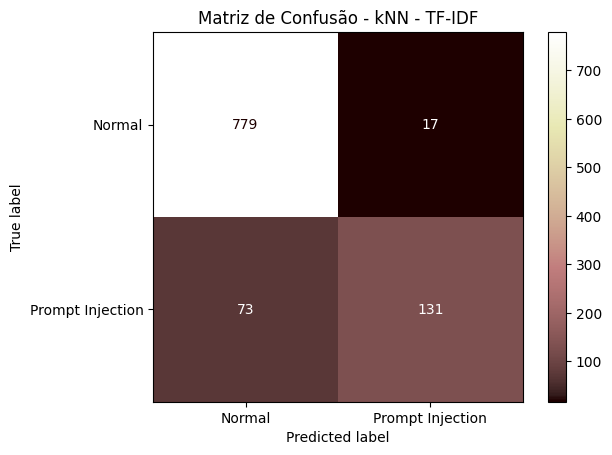

In [ ]:
print("\n Relatório - kNN TF-IDF")
print(classification_report(y_test_t, y_pred_knn_t, digits=4))

cm_t = confusion_matrix(y_test_t, y_pred_knn_t)

disp_t = ConfusionMatrixDisplay(
    confusion_matrix=cm_t,
    display_labels=["Normal", "Prompt Injection"]
)

disp_t.plot(cmap='pink')
plt.title("Matriz de Confusão - kNN - TF-IDF")
plt.show()

#### kNN + RoBERTa

In [ ]:
best_knn_r = train_knn_grid(X_train_rs, y_train_r)

In [ ]:
y_pred_knn_r = best_knn_r.predict(X_test_rs)


 Relatório - kNN RoBERTa
              precision    recall  f1-score   support

           0     0.9451    0.9724    0.9585       796
           1     0.8785    0.7794    0.8260       204

    accuracy                         0.9330      1000
   macro avg     0.9118    0.8759    0.8922      1000
weighted avg     0.9315    0.9330    0.9315      1000



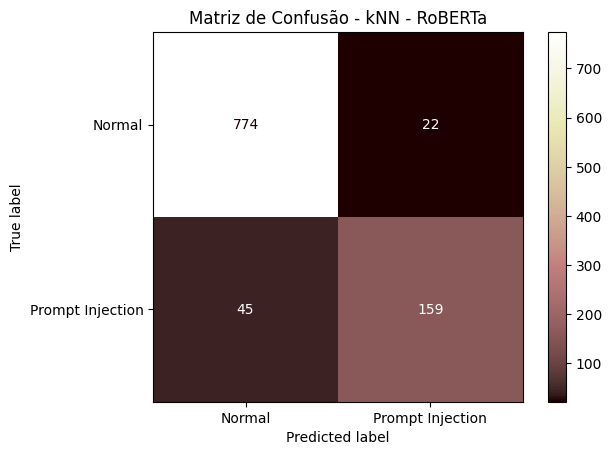

In [ ]:
print("\n Relatório - kNN RoBERTa")
print(classification_report(y_test_r, y_pred_knn_r, digits=4))

cm_r = confusion_matrix(y_test_r, y_pred_knn_r)

disp_r = ConfusionMatrixDisplay(
    confusion_matrix=cm_r,
    display_labels=["Normal", "Prompt Injection"]
)

disp_r.plot(cmap='pink')
plt.title("Matriz de Confusão - kNN - RoBERTa")
plt.show()

#### Comparação kNN

In [ ]:
# Scores (probabilidade da classe positiva)
y_scores_t = best_knn_t.predict_proba(X_test_t)[:, 1]
y_scores_r = best_knn_r.predict_proba(X_test_rs)[:, 1]

In [ ]:
# Curvas Precision-Recall
precision_t, recall_t, _ = precision_recall_curve(y_test_t, y_scores_t)
precision_r, recall_r, _ = precision_recall_curve(y_test_r, y_scores_r)

In [ ]:
# Average Precision (área sob PR curve)
ap_t = average_precision_score(y_test_t, y_scores_t)
ap_r = average_precision_score(y_test_r, y_scores_r)

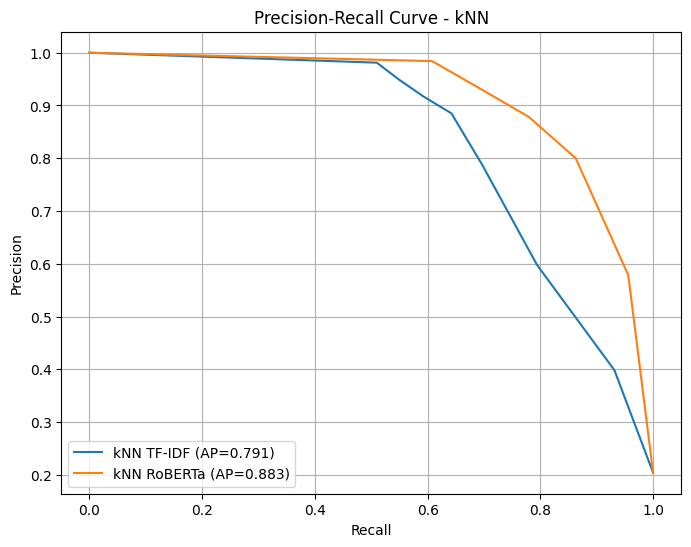

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(recall_t, precision_t, label=f'kNN TF-IDF (AP={ap_t:.3f})')
plt.plot(recall_r, precision_r, label=f'kNN RoBERTa (AP={ap_r:.3f})')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - kNN")
plt.legend()
plt.grid()
plt.show()

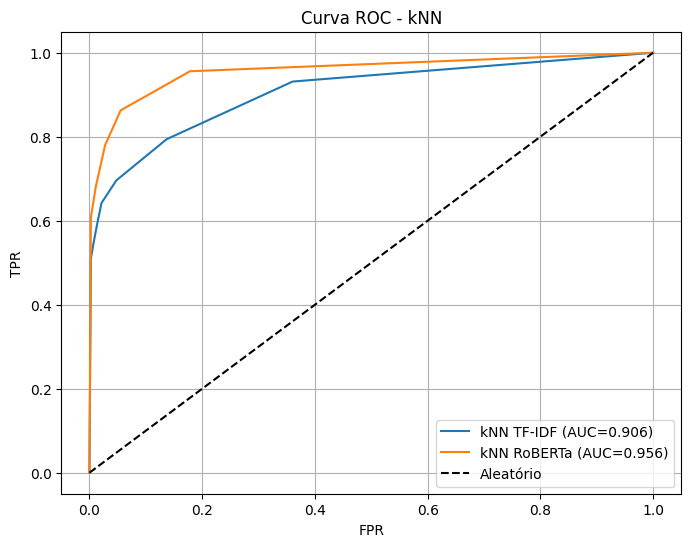

In [ ]:
# ROC
fpr_knn_t, tpr_knn_t, _ = roc_curve(y_test_t, y_scores_t)
fpr_knn_r, tpr_knn_r, _ = roc_curve(y_test_r, y_scores_r)
auc_knn_t = auc(fpr_knn_t, tpr_knn_t)
auc_knn_r = auc(fpr_knn_r, tpr_knn_r)

plt.figure(figsize=(8, 6))
plt.plot(fpr_knn_t, tpr_knn_t, label=f'kNN TF-IDF (AUC={auc_knn_t:.3f})')
plt.plot(fpr_knn_r, tpr_knn_r, label=f'kNN RoBERTa (AUC={auc_knn_r:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curva ROC - kNN")
plt.legend()
plt.grid()
plt.show()

### 3.2 Árvore de Decisão

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid_tree = {
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}

def train_tree_grid(X_train, y_train):
    grid = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        param_grid_tree,
        cv=5,
        scoring='f1',
        n_jobs=-1,
        verbose=3
    )

    grid.fit(X_train, y_train)

    print(f"Melhores hiperparâmetros: {grid.best_params_}")
    return grid.best_estimator_

####  Árvore de Decisão: Treino + avaliação TF-IDF

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Melhores hiperparâmetros: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

Relatório - Árvore de Decisão TF-IDF
              precision    recall  f1-score   support

           0     0.8873    0.8807    0.8840       796
           1     0.5476    0.5637    0.5556       204

    accuracy                         0.8160      1000
   macro avg     0.7175    0.7222    0.7198      1000
weighted avg     0.8180    0.8160    0.8170      1000



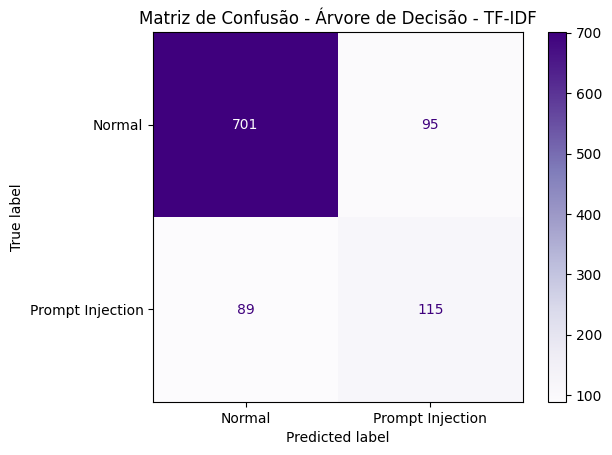

In [ ]:
best_tree_t = train_tree_grid(X_train_t, y_train_t)

y_pred_tree_t = best_tree_t.predict(X_test_t)

print("\nRelatório - Árvore de Decisão TF-IDF")
print(classification_report(y_test_t, y_pred_tree_t, digits=4))

cm = confusion_matrix(y_test_t, y_pred_tree_t)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Purples')
plt.title("Matriz de Confusão - Árvore de Decisão - TF-IDF")
plt.show()

#### Árvore de Decisão: Treino + avaliação RoBERTa

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Melhores hiperparâmetros: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5}

Relatório - Árvore de Decisão RoBERTa
              precision    recall  f1-score   support

           0     0.9134    0.9008    0.9070       796
           1     0.6326    0.6667    0.6492       204

    accuracy                         0.8530      1000
   macro avg     0.7730    0.7837    0.7781      1000
weighted avg     0.8561    0.8530    0.8544      1000



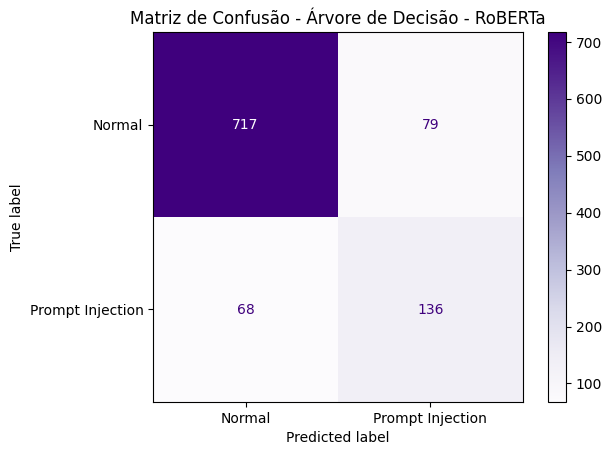

In [ ]:
best_tree_r = train_tree_grid(X_train_r, y_train_r)
y_pred_tree_r = best_tree_r.predict(X_test_r)

print("\nRelatório - Árvore de Decisão RoBERTa")
print(classification_report(y_test_r, y_pred_tree_r, digits=4))

cm = confusion_matrix(y_test_r, y_pred_tree_r)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Purples')
plt.title("Matriz de Confusão - Árvore de Decisão - RoBERTa")
plt.show()

#### Comparação Árvore de Decisão

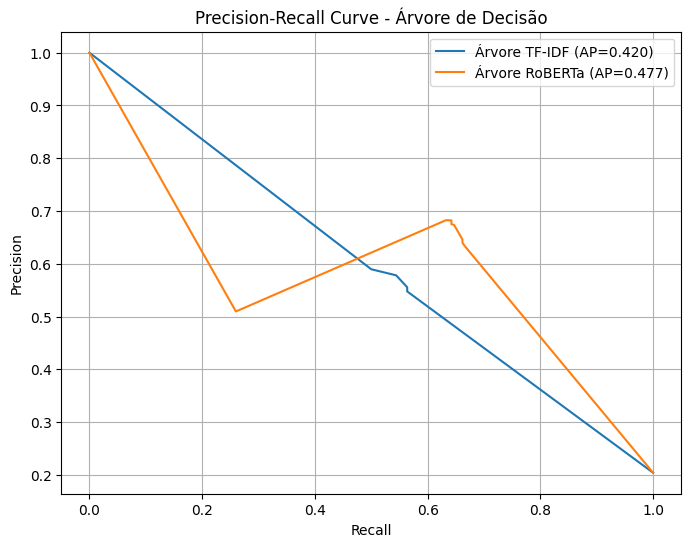

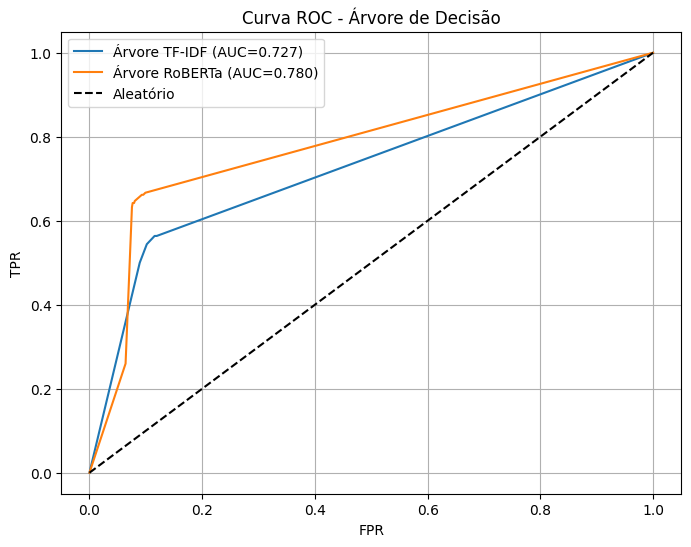

In [ ]:
# Scores via predict_proba
y_scores_tree_t = best_tree_t.predict_proba(X_test_t)[:, 1]
y_scores_tree_r = best_tree_r.predict_proba(X_test_ss)[:, 1]

# Precision-Recall
precision_tree_t, recall_tree_t, _ = precision_recall_curve(y_test_t, y_scores_tree_t)
precision_tree_r, recall_tree_r, _ = precision_recall_curve(y_test_r, y_scores_tree_r)
ap_tree_t = average_precision_score(y_test_t, y_scores_tree_t)
ap_tree_r = average_precision_score(y_test_r, y_scores_tree_r)

plt.figure(figsize=(8, 6))
plt.plot(recall_tree_t, precision_tree_t, label=f'Árvore TF-IDF (AP={ap_tree_t:.3f})')
plt.plot(recall_tree_r, precision_tree_r, label=f'Árvore RoBERTa (AP={ap_tree_r:.3f})')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Árvore de Decisão")
plt.legend()
plt.grid()
plt.show()

# ROC
fpr_tree_t, tpr_tree_t, _ = roc_curve(y_test_t, y_scores_tree_t)
fpr_tree_r, tpr_tree_r, _ = roc_curve(y_test_r, y_scores_tree_r)
auc_tree_t = auc(fpr_tree_t, tpr_tree_t)
auc_tree_r = auc(fpr_tree_r, tpr_tree_r)

plt.figure(figsize=(8, 6))
plt.plot(fpr_tree_t, tpr_tree_t, label=f'Árvore TF-IDF (AUC={auc_tree_t:.3f})')
plt.plot(fpr_tree_r, tpr_tree_r, label=f'Árvore RoBERTa (AUC={auc_tree_r:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curva ROC - Árvore de Decisão")
plt.legend()
plt.grid()
plt.show()

### 3.3 Perceptron

In [ ]:
from sklearn.linear_model import Perceptron

#### Perceptron: Treino + avaliação TF-IDF

In [ ]:
perceptron_model_t = Perceptron(
    penalty=None,
    alpha=0.0001,
    l1_ratio=0.15,
    fit_intercept=True,
    max_iter=1000,
    tol=0.001,
    shuffle=True,
    eta0=1.0,
    random_state=42,
    early_stopping=False,
    validation_fraction=0.1,
    n_iter_no_change=5,
    class_weight='balanced',
)

# Treinamento
perceptron_model_t.fit(X_train_t, y_train_t)

Perceptron(class_weight='balanced', random_state=42)


Relatório - Perceptron TF-IDF
              precision    recall  f1-score   support

           0     0.9432    0.9171    0.9299       796
           1     0.7080    0.7843    0.7442       204

    accuracy                         0.8900      1000
   macro avg     0.8256    0.8507    0.8371      1000
weighted avg     0.8952    0.8900    0.8920      1000



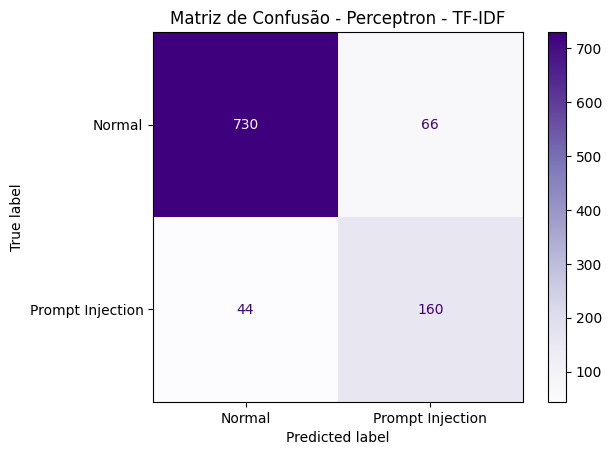

In [ ]:
y_pred_perceptron_t = perceptron_model_t.predict(X_test_t)
print("\nRelatório - Perceptron TF-IDF")
print(classification_report(y_test_t, y_pred_perceptron_t, digits=4))

cm = confusion_matrix(y_test_t, y_pred_perceptron_t)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Purples')
plt.title("Matriz de Confusão - Perceptron - TF-IDF")
plt.show()

#### Perceptron: Treino + avaliação RoBERTa

In [ ]:
perceptron_model_r = Perceptron(
    penalty=None,
    alpha=0.0001,
    l1_ratio=0.15,
    fit_intercept=True,
    max_iter=1000,
    tol=0.001,
    shuffle=True,
    eta0=1.0,
    random_state=42,
    early_stopping=False,
    validation_fraction=0.1,
    n_iter_no_change=5,
    class_weight='balanced',
)


# Treinamento com dados normalizados com StandardScaler
perceptron_model_r.fit(X_train_ss, y_train_r)

Perceptron(class_weight='balanced', random_state=42)


Relatório - Perceptron RoBERTa
              precision    recall  f1-score   support

           0     0.9652    0.9410    0.9529       796
           1     0.7902    0.8676    0.8271       204

    accuracy                         0.9260      1000
   macro avg     0.8777    0.9043    0.8900      1000
weighted avg     0.9295    0.9260    0.9273      1000



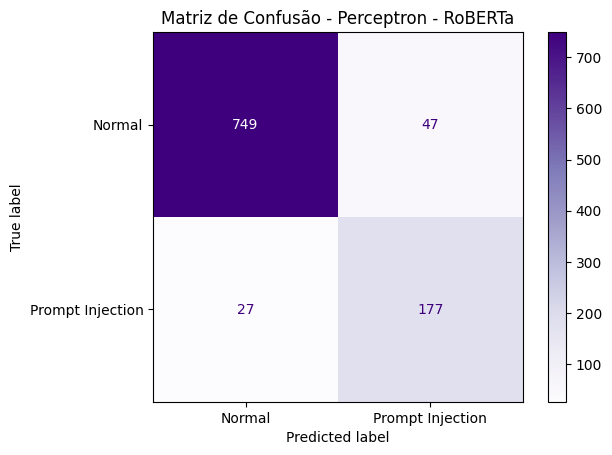

In [ ]:
y_pred_perceptron_r = perceptron_model_r.predict(X_test_ss)
print("\nRelatório - Perceptron RoBERTa")
print(classification_report(y_test_r, y_pred_perceptron_r, digits=4))

cm = confusion_matrix(y_test_r, y_pred_perceptron_r)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Purples')
plt.title("Matriz de Confusão - Perceptron - RoBERTa")
plt.show()

#### Comparação Perceptron

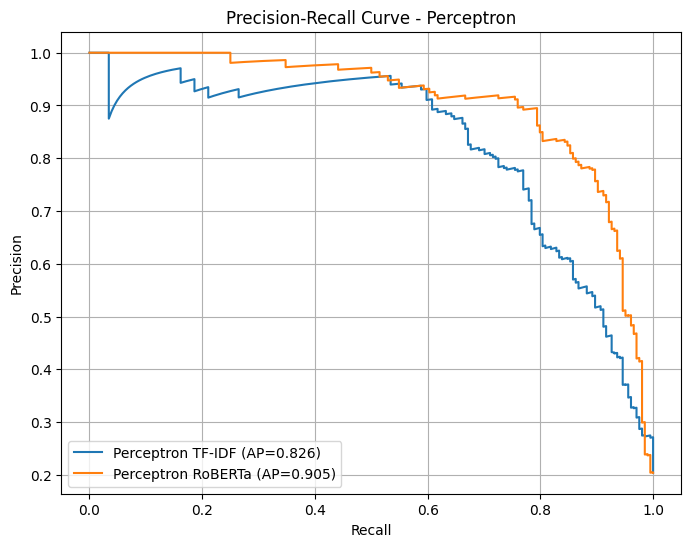

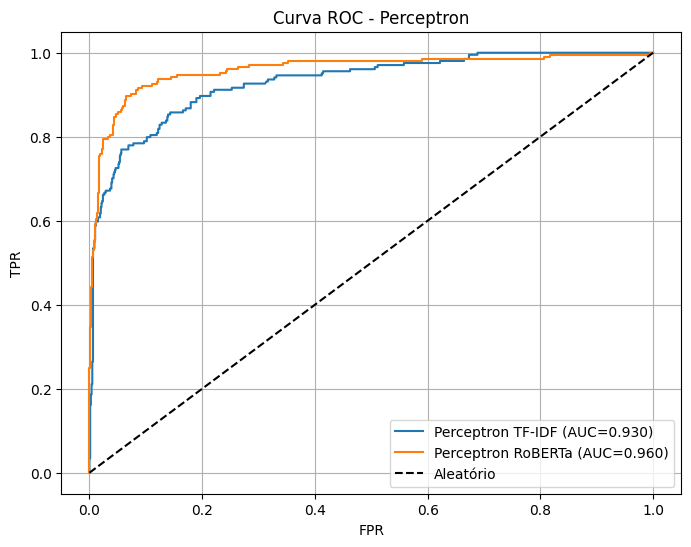

In [ ]:
# Scores via decision_function
y_scores_perc_t = perceptron_model_t.decision_function(X_test_t)
y_scores_perc_r = perceptron_model_r.decision_function(X_test_ss)

# Precision-Recall
precision_perc_t, recall_perc_t, _ = precision_recall_curve(y_test_t, y_scores_perc_t)
precision_perc_r, recall_perc_r, _ = precision_recall_curve(y_test_r, y_scores_perc_r)
ap_perc_t = average_precision_score(y_test_t, y_scores_perc_t)
ap_perc_r = average_precision_score(y_test_r, y_scores_perc_r)

plt.figure(figsize=(8, 6))
plt.plot(recall_perc_t, precision_perc_t, label=f'Perceptron TF-IDF (AP={ap_perc_t:.3f})')
plt.plot(recall_perc_r, precision_perc_r, label=f'Perceptron RoBERTa (AP={ap_perc_r:.3f})')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Perceptron")
plt.legend()
plt.grid()
plt.show()

# ROC
fpr_perc_t, tpr_perc_t, _ = roc_curve(y_test_t, y_scores_perc_t)
fpr_perc_r, tpr_perc_r, _ = roc_curve(y_test_r, y_scores_perc_r)
auc_perc_t = auc(fpr_perc_t, tpr_perc_t)
auc_perc_r = auc(fpr_perc_r, tpr_perc_r)

plt.figure(figsize=(8, 6))
plt.plot(fpr_perc_t, tpr_perc_t, label=f'Perceptron TF-IDF (AUC={auc_perc_t:.3f})')
plt.plot(fpr_perc_r, tpr_perc_r, label=f'Perceptron RoBERTa (AUC={auc_perc_r:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curva ROC - Perceptron")
plt.legend()
plt.grid()
plt.show()

### 3.4 Support Vector Machine

Os hiperparâmetros do SVM serão escolhidos automaticamente pelo GridSearchCV. O parâmetro C controla o grau de penalização de erros de classificação, influenciando o equilíbrio entre margem e ajuste aos dados. O kernel utilizado foi o RBF, adequado para capturar relações não lineares em dados de alta dimensionalidade. Já o parâmetro gamma define o alcance da influência de cada ponto no espaço de decisão.

Para a otimização, foi utilizada validação cruzada com 5 folds e a métrica F1-score, adequada para cenários com desbalanceamento entre classes. Além disso, foi aplicada a estratégia class_weight='balanced', que ajusta automaticamente o peso das classes para reduzir viés em direção à classe majoritária.

In [ ]:
from sklearn.svm import SVC

In [ ]:
param_grid_svm = {
    'C': [0.1, 1, 10], # diferentes valores para controlar a penalização
    'kernel': ['rbf'], ## rbf para capturar relaçoes nao lineares
    'gamma': ['scale', 'auto'] ## define o alcance da influência de cada ponto no kernel
}

In [ ]:
def train_svm_grid(X_train, y_train):
    grid = GridSearchCV(
        SVC(class_weight='balanced'),  # penalização ajustada para desbalanceamento
        param_grid_svm,
        cv=5,               # validação cruzada com 5 folds
        scoring='f1', #para selecionar o melhor modelo baseado no f1 score
        n_jobs=-1           # usa todos os núcleos do processador
    )

    grid.fit(X_train, y_train) # treina com todas as combinações possiveis
    return grid.best_estimator_ #retorna o melhor

#### SVM + TF-IDF

In [ ]:
best_svm_t = train_svm_grid(X_train_t, y_train_t)

In [ ]:
y_pred_svm_t = best_svm_t.predict(X_test_t)


 Relatório - SVM TF-IDF
              precision    recall  f1-score   support

           0     0.9421    0.9611    0.9515       796
           1     0.8351    0.7696    0.8010       204

    accuracy                         0.9220      1000
   macro avg     0.8886    0.8653    0.8763      1000
weighted avg     0.9203    0.9220    0.9208      1000



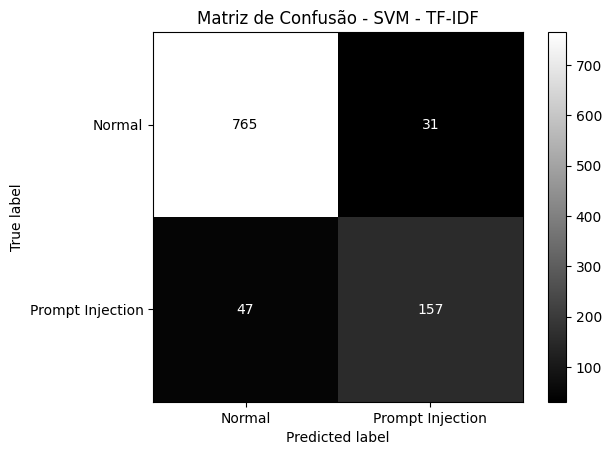

In [ ]:
print("\n Relatório - SVM TF-IDF")
print(classification_report(y_test_t, y_pred_svm_t, digits=4))

cm_t = confusion_matrix(y_test_t, y_pred_svm_t)

disp_t = ConfusionMatrixDisplay(
    confusion_matrix=cm_t,
    display_labels=["Normal", "Prompt Injection"]
)

disp_t.plot(cmap='gray')
plt.title("Matriz de Confusão - SVM - TF-IDF")
plt.show()

#### SVM + RoBERTa

In [ ]:
best_svm_r = train_svm_grid(X_train_rs, y_train_r)

In [ ]:
y_pred_svm_r = best_svm_r.predict(X_test_rs)


 Relatório - SVM RoBERTa
              precision    recall  f1-score   support

           0     0.9584    0.9849    0.9715       796
           1     0.9341    0.8333    0.8808       204

    accuracy                         0.9540      1000
   macro avg     0.9463    0.9091    0.9262      1000
weighted avg     0.9535    0.9540    0.9530      1000



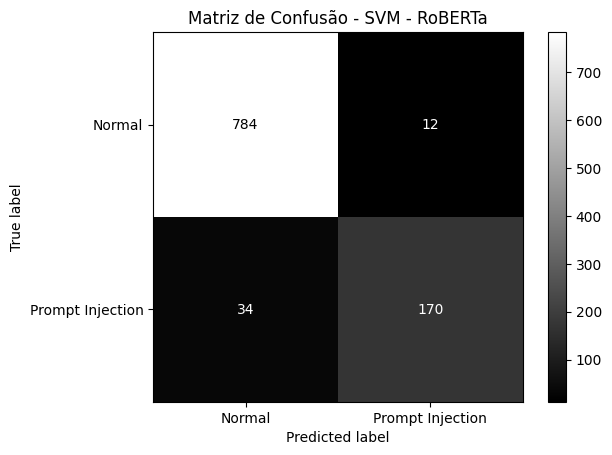

In [ ]:
print("\n Relatório - SVM RoBERTa")
print(classification_report(y_test_r, y_pred_svm_r, digits=4))

cm_r = confusion_matrix(y_test_r, y_pred_svm_r)

disp_r = ConfusionMatrixDisplay(
    confusion_matrix=cm_r,
    display_labels=["Normal", "Prompt Injection"]
)

disp_r.plot(cmap='gray')
plt.title("Matriz de Confusão - SVM - RoBERTa")
plt.show()

#### Comparação SVM

In [ ]:
# scores (SVM usa decision_function)
y_scores_t = best_svm_t.decision_function(X_test_t)
y_scores_r = best_svm_r.decision_function(X_test_rs)

In [ ]:
precision_t, recall_t, _ = precision_recall_curve(y_test_t, y_scores_t)
precision_r, recall_r, _ = precision_recall_curve(y_test_r, y_scores_r)

In [ ]:
ap_t = average_precision_score(y_test_t, y_scores_t)
ap_r = average_precision_score(y_test_r, y_scores_r)

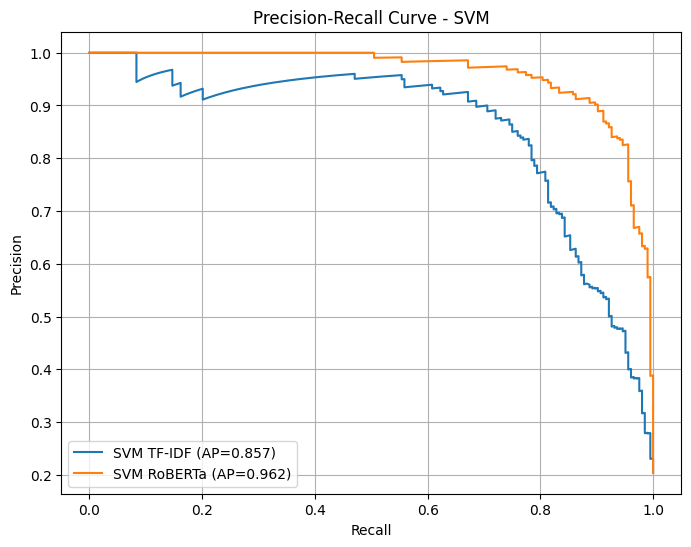

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(recall_t, precision_t, label=f'SVM TF-IDF (AP={ap_t:.3f})')
plt.plot(recall_r, precision_r, label=f'SVM RoBERTa (AP={ap_r:.3f})')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - SVM")
plt.legend()
plt.grid()
plt.show()

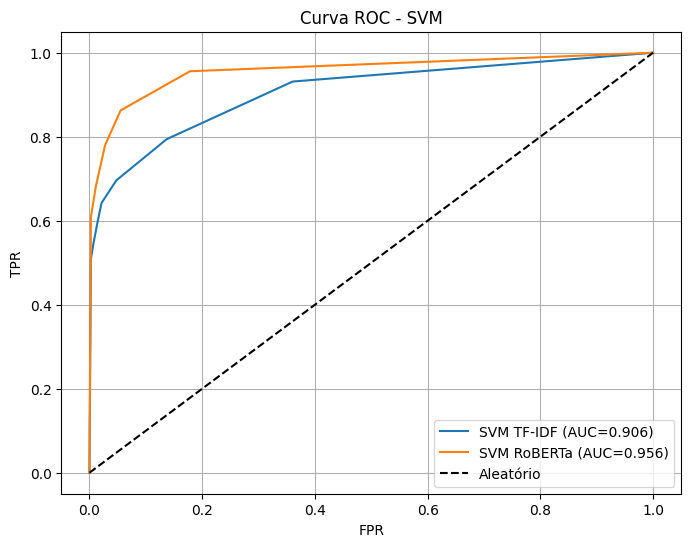

In [ ]:
# ROC
fpr_svm_t, tpr_svm_t, _ = roc_curve(y_test_t, y_scores_t)
fpr_svm_r, tpr_svm_r, _ = roc_curve(y_test_r, y_scores_r)
auc_svm_t = auc(fpr_svm_t, tpr_svm_t)
auc_svm_r = auc(fpr_svm_r, tpr_svm_r)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm_t, tpr_svm_t, label=f'SVM TF-IDF (AUC={auc_svm_t:.3f})')
plt.plot(fpr_svm_r, tpr_svm_r, label=f'SVM RoBERTa (AUC={auc_svm_r:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curva ROC - SVM")
plt.legend()
plt.grid()
plt.show()

### 3.5 Shrinkage Discriminant Analysis

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.covariance import OAS

#### SDA + TF-IDF

In [ ]:
# Shrinkage é um parâmetro
# Com shrinkage = 'auto', é usado o estimador de covariância Ledoit Wolf
sda_model_t_auto = LinearDiscriminantAnalysis(
    solver='lsqr',                    # Só 'lsqr' aceita shrinkage ativado, é obrigatório
    shrinkage='auto',                 # Pode assumir valores no intervalo [0,1] ou auto -> seria o valor ótimo
                                      # 0: sem shrinkage; 1: shrinkage completo (pega a diagonal da matriz de variância)
    priors=np.array([0.8, 0.2]),
    tol=0.0001,
  )

sda_model_t_auto.fit(X_train_t, y_train_t)

LinearDiscriminantAnalysis(priors=array([0.8, 0.2]), shrinkage='auto',
                           solver='lsqr')

In [ ]:
# Experimentação pela abordagem do estimador de covariância OAS
oas = OAS().fit(X_train_t)
shrinkage_oas = oas.shrinkage_
print(f"λ OAS         : {shrinkage_oas:.4f}")           # É um valor pequeno, não foram identificados muitos embbedings irrelevantes

sda_model_t_oas = LinearDiscriminantAnalysis(
    solver='lsqr',                    # Só 'lsqr' aceita shrinkage ativado, é obrigatório
    shrinkage= shrinkage_oas,         # Valor gerado a partir das instâncias de treinamento
    priors=np.array([0.8, 0.2]),      # Desbalanceamento do dataset
    tol=0.0001,
  )

sda_model_t_oas.fit(X_train_t, y_train_t)

λ OAS         : 0.0495


LinearDiscriminantAnalysis(priors=array([0.8, 0.2]),
                           shrinkage=np.float32(0.049508564), solver='lsqr')

In [ ]:
# Validação cruzada
models_SDA_t = {"SDA + Ledoit Wolf": sda_model_t_auto, "SDA + OAS": sda_model_t_oas}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models_SDA_t.items():
    scores = cross_validate(
        model, X_train_t, y_train_t,
        cv=cv,
        scoring=["accuracy", "f1_weighted", "roc_auc"],
        return_train_score=True,
        n_jobs=-1
    )
    results.append({
        "modelo"   : name,
        "acc_val"  : scores["test_accuracy"].mean(),
        "acc_std"  : scores["test_accuracy"].std(),
        "f1_val"   : scores["test_f1_weighted"].mean(),
        "f1_std"   : scores["test_f1_weighted"].std(),
        "auc_val"  : scores["test_roc_auc"].mean(),
        "acc_train": scores["train_accuracy"].mean(),
    })

df_cv_sda_t = pd.DataFrame(results)

# SDA + OAS tem desempenho levemente melhor que SDA + Ledoit Wolf (no conjunto de validação)
print("Comparativo do SDA - TF-IDF no Cross-Validation")
print(df_cv_sda_t.to_string(index=False, float_format="%.4f"))

Comparativo do SDA - TF-IDF no Cross-Validation
           modelo  acc_val  acc_std  f1_val  f1_std  auc_val  acc_train
SDA + Ledoit Wolf   0.9192   0.0126  0.9123  0.0149   0.9492     0.9273
        SDA + OAS   0.9252   0.0096  0.9210  0.0106   0.9518     0.9354


In [ ]:
# Avaliação no conjunto de teste
test_results_sda_t = []

for name, model in models_SDA_t.items():
    model.fit(X_train_t, y_train_t)
    y_pred  = model.predict(X_test_t)
    y_proba = model.predict_proba(X_test_t)[:, 1]

    test_results_sda_t.append({
        "modelo"     : name,
        "acc_test"   : accuracy_score(y_test_t, y_pred),
        "f1_test"    : f1_score(y_test_t, y_pred, average='weighted'),
        "auc_test"   : roc_auc_score(y_test_t, y_proba),
    })

df_test_sda_t = pd.DataFrame(test_results_sda_t)

print("Comparativo do SDA - TF-IDF no conjunto de teste")
print(df_test_sda_t.to_string(index=False, float_format="%.4f"))

Comparativo do SDA - TF-IDF no conjunto de teste
           modelo  acc_test  f1_test  auc_test
SDA + Ledoit Wolf    0.9070   0.8980    0.9364
        SDA + OAS    0.9040   0.8961    0.9364


In [ ]:
# Aqui, SDA + Ledoit Wolf apresenta desempenho levemente acima de SDA + OAS
for name, model in models_SDA_t.items():
    y_pred = model.predict(X_test_t)
    print(f"\n▶ {name}")
    print(classification_report(y_test_t, y_pred, target_names=["Normal", "Prompt Injection"]))


▶ SDA + Ledoit Wolf
                  precision    recall  f1-score   support

          Normal       0.90      0.99      0.94       796
Prompt Injection       0.94      0.58      0.72       204

        accuracy                           0.91      1000
       macro avg       0.92      0.78      0.83      1000
    weighted avg       0.91      0.91      0.90      1000


▶ SDA + OAS
                  precision    recall  f1-score   support

          Normal       0.90      0.98      0.94       796
Prompt Injection       0.90      0.59      0.72       204

        accuracy                           0.90      1000
       macro avg       0.90      0.79      0.83      1000
    weighted avg       0.90      0.90      0.90      1000



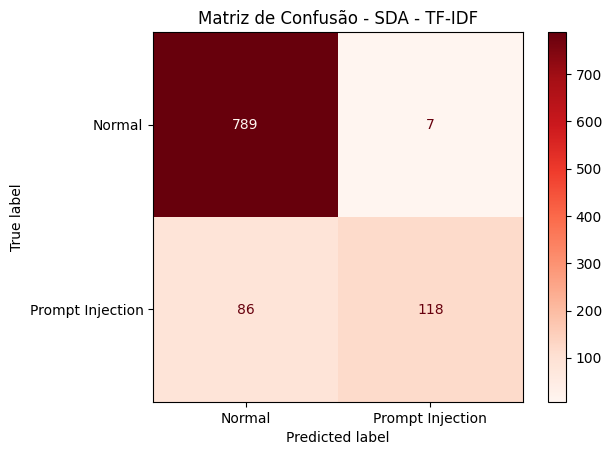

In [ ]:
# Matriz de confusão do modelo de melhor desempenho (SDA + Ledoit Wolf)
y_pred_sda_t = sda_model_t_auto.predict(X_test_t)
cm = confusion_matrix(y_test_t, y_pred_sda_t)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Reds')
plt.title("Matriz de Confusão - SDA - TF-IDF")
plt.show()

#### SDA + RoBERTa

In [ ]:
# Experimentação pela abordagem do estimador de covariância OAS
oas_r = OAS().fit(X_train_r)
shrinkage_oas_r = oas_r.shrinkage_
print(f"λ OAS         : {shrinkage_oas_r:.4f}")

# Definição dos modelos de comparação
models_SDA_r = {
    "SDA + Ledoit Wolf": Pipeline([           # auto
        ("scaler", StandardScaler()),
        ("sda", LinearDiscriminantAnalysis(
            solver='lsqr',
            shrinkage='auto',
            priors=np.array([0.8, 0.2]),
            tol=0.0001,
        ))
    ]),
    "SDA + OAS": Pipeline([                    # dado o conjunto de treino
        ("scaler", StandardScaler()),
        ("sda", LinearDiscriminantAnalysis(
            solver='lsqr',
            shrinkage=shrinkage_oas_r,
            priors=np.array([0.8, 0.2]),
            tol=0.0001,
        ))
    ]),
}

λ OAS         : 0.0023


In [ ]:
# Pipeline está sendo aplicado aqui, pois o conjunto de treinamento deve ser normalizado sem o risco de dataleakage
# Isso não foi necessário com o cenário de TF-IDF, pois os dados não foram normalizados
cv_r  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_r = []

for name, pipe in models_SDA_r.items():
    scores = cross_validate(
        pipe, X_train_r, y_train_r,                     # dados não normalizados
        cv=cv_r,
        scoring=["accuracy", "f1_weighted", "roc_auc"],
        return_train_score=True,
        n_jobs=-1
    )
    results_r.append({
        "modelo"   : name,
        "acc_val"  : scores["test_accuracy"].mean(),
        "acc_std"  : scores["test_accuracy"].std(),
        "f1_val"   : scores["test_f1_weighted"].mean(),
        "f1_std"   : scores["test_f1_weighted"].std(),
        "auc_val"  : scores["test_roc_auc"].mean(),
        "acc_train": scores["train_accuracy"].mean(),
    })

df_cv_sda_r = pd.DataFrame(results_r)
print("Comparativo do SDA - RoBERTa no Cross-Validation")
print(df_cv_sda_r.to_string(index=False, float_format="%.4f"))

Comparativo do SDA - RoBERTa no Cross-Validation
           modelo  acc_val  acc_std  f1_val  f1_std  auc_val  acc_train
SDA + Ledoit Wolf   0.9530   0.0100  0.9520  0.0104   0.9810     0.9750
        SDA + OAS   0.9537   0.0104  0.9529  0.0108   0.9798     0.9813


In [ ]:
sda_model_r_auto = models_SDA_r["SDA + Ledoit Wolf"]
sda_model_r_oas = models_SDA_r["SDA + OAS"]

print("Comparativo do SDA - RoBERTa")
models_SDA_r = {
    "SDA + Ledoit Wolf": sda_model_r_auto,
    "SDA + OAS": sda_model_r_oas }
test_results_sda_r = []

for name, model in models_SDA_r.items():
    model.fit(X_train_ss, y_train_r)      # modelo retreinado com todo o dataset normalizado

    y_pred  = model.predict(X_test_ss)
    y_proba = model.predict_proba(X_test_ss)[:, 1]

    test_results_sda_r.append({
        "modelo"  : name,
        "acc_test": accuracy_score(y_test_r, y_pred),
        "f1_test" : f1_score(y_test_r, y_pred, average='weighted'),
        "auc_test": roc_auc_score(y_test_r, y_proba),
    })

    print(f"\n▶ {name}")
    print(classification_report(y_test_r, y_pred,
                                target_names=["Normal", "Prompt Injection"]))

df_test_sda_r = pd.DataFrame(test_results_sda_r)

Comparativo do SDA - RoBERTa

▶ SDA + Ledoit Wolf
                  precision    recall  f1-score   support

          Normal       0.94      0.98      0.96       796
Prompt Injection       0.91      0.75      0.83       204

        accuracy                           0.94      1000
       macro avg       0.93      0.87      0.89      1000
    weighted avg       0.93      0.94      0.93      1000


▶ SDA + OAS
                  precision    recall  f1-score   support

          Normal       0.94      0.98      0.96       796
Prompt Injection       0.90      0.77      0.83       204

        accuracy                           0.94      1000
       macro avg       0.92      0.87      0.89      1000
    weighted avg       0.93      0.94      0.93      1000



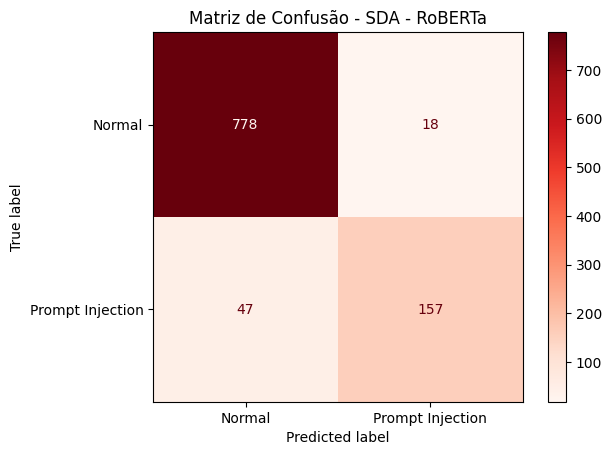

In [ ]:
# Matriz de confusão do modelo de melhor desempenho (SDA + OAS)
y_pred_sda_r = sda_model_r_oas.predict(X_test_ss)
cm = confusion_matrix(y_test_r, y_pred_sda_r)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prompt Injection"])
disp.plot(cmap='Reds')
plt.title("Matriz de Confusão - SDA - RoBERTa")
plt.show()

### Comparação SDA

In [ ]:
# Preparação para gerar gráfico comparativo
y_scores_t_sda = sda_model_t_auto.decision_function(X_test_t)
y_scores_r_sda = sda_model_r_oas.decision_function(X_test_ss)

precision_t_sda, recall_t_sda, _ = precision_recall_curve(y_test_t, y_scores_t_sda)
precision_r_sda, recall_r_sda, _ = precision_recall_curve(y_test_r, y_scores_r_sda)

ap_t_sda = average_precision_score(y_test_t, y_scores_t_sda)
ap_r_sda = average_precision_score(y_test_r, y_scores_r_sda)

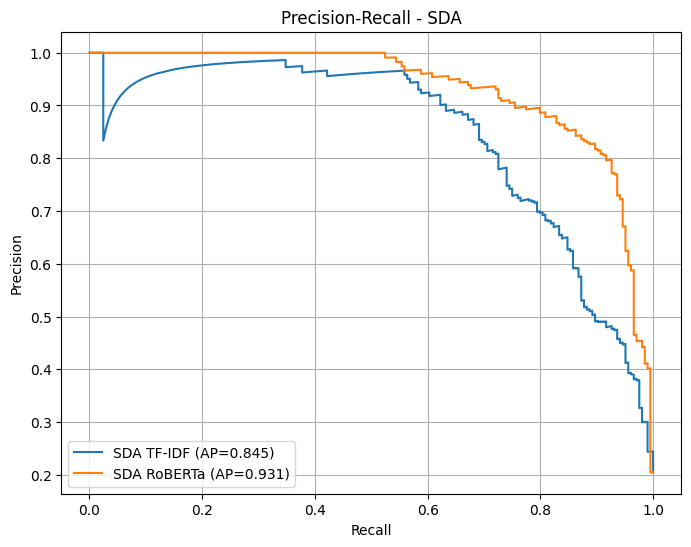

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(recall_t_sda, precision_t_sda, label=f'SDA TF-IDF (AP={ap_t_sda:.3f})')
plt.plot(recall_r_sda, precision_r_sda, label=f'SDA RoBERTa (AP={ap_r_sda:.3f})')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall - SDA")
plt.legend()
plt.grid()
plt.show()

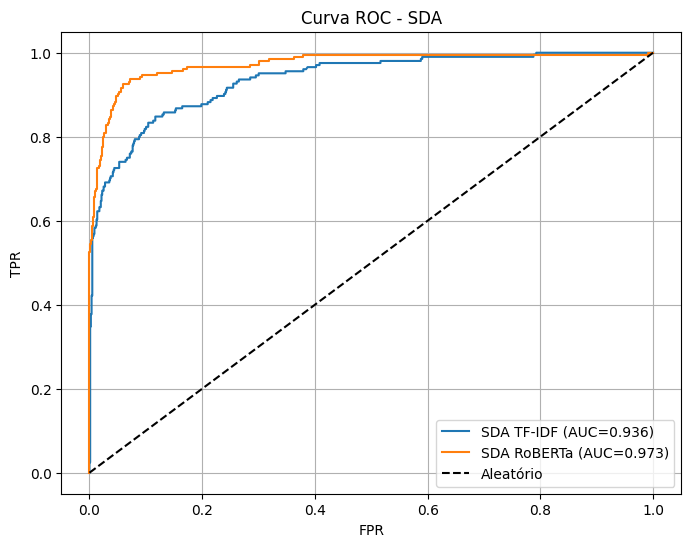

In [ ]:
# ROC
fpr_sda_t, tpr_sda_t, _ = roc_curve(y_test_t, y_scores_t_sda)
fpr_sda_r, tpr_sda_r, _ = roc_curve(y_test_r, y_scores_r_sda)
auc_sda_t = auc(fpr_sda_t, tpr_sda_t)
auc_sda_r = auc(fpr_sda_r, tpr_sda_r)

plt.figure(figsize=(8, 6))
plt.plot(fpr_sda_t, tpr_sda_t, label=f'SDA TF-IDF (AUC={auc_sda_t:.3f})')
plt.plot(fpr_sda_r, tpr_sda_r, label=f'SDA RoBERTa (AUC={auc_sda_r:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curva ROC - SDA")
plt.legend()
plt.grid()
plt.show()

### Referências

Modelo kNN: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

Modelo Decision Tree: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier

Modelo Perceptron: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html

Modelo SVM: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

Modelo SDA: https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html